# Style Sheet

In [1]:
import matplotlib.pyplot as plt
import numpy as np
plt.style.use(r'style_sheets/base.mplstyle')

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from matplotlib.font_manager import FontProperties
 
 
# SI length ladder (value of each prefix in metres), low -> high
_SI_ORDER = [("pm", 1e-12), ("nm", 1e-9), ("µm", 1e-6),
             ("mm", 1e-3), ("cm", 1e-2), ("m", 1.0)]
_SI = dict(_SI_ORDER) | {"um": 1e-6}  # accept ASCII 'um' as an alias
 
 
def _nice_125(x):
    """Snap x>0 to the nearest {1,2,5}x10^n value, measured in log space."""
    if x <= 0:
        return x
    exp = np.floor(np.log10(x))
    mantissa = x / 10.0 ** exp                       # in [1, 10)
    candidates = np.array([1.0, 2.0, 5.0, 10.0])     # 10 catches top of decade
    m = candidates[np.argmin(np.abs(np.log(candidates) - np.log(mantissa)))]
    return m * 10.0 ** exp
 
 
def _format_length(value, units, scale=True):
    """Relabel a length with the most readable SI prefix (physical size fixed)."""
    if not scale or units not in _SI:
        return f"{value:g} {units}"
    metres = value * _SI[units]
    name, fac = _SI_ORDER[0]
    for n, f in _SI_ORDER:                            # largest prefix with mantissa >= 1
        if metres >= f:
            name, fac = n, f
    return f"{metres / fac:g} {name}"
 
 
def add_scalebar(ax, dx, units="nm", length_fraction=0.1,
                 loc="lower right", color="black", box_alpha=0.0,
                 height_fraction=0.01, sep=4, pad=0.4,
                 fontsize=None, label_top=False, scale_units=True):
    """
    Add a physical scale bar to `ax`.
 
    Parameters
    ----------
    ax : matplotlib.axes.Axes
    dx : float
        Physical size of one data unit (e.g. nm per pixel).
    units : str
        Units of `dx`. Length units (pm, nm, µm/um, mm, cm, m) auto-rescale
        for the label when `scale_units` is True.
    length_fraction : float
        Target fraction f of the x-axis the bar should span; the drawn length
        is the {1,2,5}x10^n value closest (in log) to f * W * dx.
    loc : str or int
        Anchor location, e.g. 'lower right'.
    color : str
        Bar and text colour ('white' is usual on dark micrographs).
    box_alpha : float
        Background box opacity; 0 -> no frame.
    height_fraction : float
        Bar thickness as a fraction of the y-axis range.
    sep : float
        Gap (pt) between bar and label.
    pad : float
        Padding (in fontsize units) inside the anchored box.
    fontsize : float or None
    label_top : bool
        Put the label above the bar instead of below.
    scale_units : bool
        Auto-pick a readable SI prefix for the label.
 
    Returns
    -------
    AnchoredSizeBar
    """
    # axis extent in data units
    x0, x1 = ax.get_xlim()
    W = abs(x1 - x0)
 
    # target physical length -> nice value -> length back in data units
    nice = _nice_125(length_fraction * W * dx)
    size_data = nice / dx
 
    # bar thickness in data units
    y0, y1 = ax.get_ylim()
    size_vertical = height_fraction * abs(y1 - y0)
 
    label = _format_length(nice, units, scale=scale_units)
    fontprops = FontProperties(size=fontsize) if fontsize is not None else None
 
    bar = AnchoredSizeBar(
        ax.transData,
        size_data,
        label,
        loc=loc,
        pad=pad,
        sep=sep,
        color=color,
        frameon=(box_alpha > 0),
        size_vertical=size_vertical,
        label_top=label_top,
        fontproperties=fontprops,
    )
    if box_alpha > 0:                                # match box_alpha semantics
        bar.patch.set_alpha(box_alpha)
        bar.patch.set_facecolor("white")
        bar.patch.set_edgecolor("none")
 
    ax.add_artist(bar)
    return bar


from pathlib import Path

def save_fig(fig=None, path="figure", *, dpi=600, transparent=True,
             pad_inches=0.05, editable_text=False, also=None):
    """Save a Matplotlib figure as a publication-ready SVG.

    Parameters
    ----------
    fig : Figure, optional
        Figure to save. Defaults to the current figure (plt.gcf()).
    path : str or Path
        Output path. A '.svg' suffix is added if missing.
    dpi : int
        Resolution of *embedded raster layers only* (e.g. imshow images);
        vector elements are unaffected. 600 keeps micrographs crisp.
    transparent : bool
        Transparent figure/axes background (lets the SVG sit on any page color).
    pad_inches : float
        Padding around the tight bounding box, in inches.
    editable_text : bool
        If True, keep glyphs as <text> (editable in Illustrator/Inkscape,
        smaller files). Ignored when text.usetex=True, since LaTeX emits paths.
    also : str or list of str, optional
        Extra formats to write alongside the SVG, e.g. 'pdf' or ['pdf', 'png'].
    """
    fig = fig or plt.gcf()
    path = Path(path).with_suffix(".svg")
    path.parent.mkdir(parents=True, exist_ok=True)

    if editable_text and not plt.rcParams.get("text.usetex", False):
        plt.rcParams["svg.fonttype"] = "none"

    kw = dict(dpi=dpi, transparent=transparent,
              bbox_inches="tight", pad_inches=pad_inches)

    fig.savefig(path, **kw)

    if also:
        for fmt in ([also] if isinstance(also, str) else also):
            fig.savefig(path.with_suffix(f".{fmt}"), **kw)

    return path


In [2]:
import h5py
import os

class SingleParticle():
    def __init__(self, x,y,z):
        self.traj_x = x
        self.traj_y = y
        self.traj_z = z

def LoadDataset(file_name):
    '''
    Loads the h5 dataset developed by martin's TracesROi_to_z_analysis.py script.
    '''
    dataset_all = []
    # Open the file in read mode
    with h5py.File(file_name, 'r') as f:
        #print(f"Keys in the HDF5 file: {list(f.keys())}")
        
        # Iterate through keys and print their types
        for key in f.keys():
            #print(f"Object name: {key}, Object type: {type(f[key])}")
            dset = f[key] # this is a croup with N_particles which are all 'members'
            for particle_index in dset:
                #print(dset[particle_index].keys())

                # this reads in a pointer
                grp = dset[particle_index]
                # This accesses the memory directly
                curr_particle = SingleParticle(
                    grp['x'][:],
                    grp['y'][:],
                    grp['z'][:],
                    #grp['diffusion_msd'][()],
                    #grp['diffusion_confined'][()],
                    #grp['length_confined'][()]
                )
                # append the data to the dataset file
                dataset_all.append(curr_particle)

    print(f'Particles in Current Dataset: {len(dataset_all)}')
    return dataset_all

# PBS Series

In [3]:
# List of Datasets For Figure 1
# Polystyrene + PBS
PS_PBS0p1_225nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p1\ClicOnLeft2\ClicOnLeft2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
PS_PBS0p01_225nm  = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p01\center2\center2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
PS_PBS0p001_225nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_2\center_2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
#PS_PBS0p001_300nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_3\center_3radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
#PS_PBS0p001_375nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_4\center_4radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
PS_PBS0p00001_225nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p00001\ClicOnLeft_2\ClicOnLeft_2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")

Particles in Current Dataset: 8
Particles in Current Dataset: 53
Particles in Current Dataset: 13
Particles in Current Dataset: 62


In [88]:
from hdr.transverse_estimation import Traj_XY_confinement_to_radius
from hdr.transverse_estimation import getMeanSquaredDisplacement
from hdr.axial_estimation import LineAnalyticalMSD
from tqdm import tqdm
from scipy.optimize import curve_fit

def GetHistFWHM(data, bins=10):
    # 1. Compute the histogram
    counts, bin_edges = np.histogram(data, bins=bins)
    
    # 2. Get the centers of the bins
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # 3. Find the maximum height of the peak
    max_idx = np.argmax(counts)
    max_val = counts[max_idx]
    half_max = max_val / 2.0
    
    # 4. Find the crossing points using interpolation 
    # Left of the peak
    hist_left = counts[:max_idx]
    bin_left = bin_centers[:max_idx]
    # Find the nearest elements to half_max
    left_idx = np.where(hist_left <= half_max)[0]
    if len(left_idx) == 0:
        return None  # Peak doesn't drop below half_max on the left
    
    # Take the index closest to the peak on the left
    x1 = np.interp(half_max, 
                   [hist_left[left_idx[-1]-1], hist_left[left_idx[-1]]], 
                   [ bin_left[left_idx[-1]-1],  bin_left[left_idx[-1]]])
    
    # Right of the peak
    hist_right = counts[max_idx:]
    bin_right = bin_centers[max_idx:]
    right_idx = np.where(hist_right <= half_max)[0]
    if len(right_idx) == 0:
        return None  # Peak doesn't drop below half_max on the right
    
    # Take the first index that drops below half_max on the right
    x2 = np.interp(half_max, [hist_right[right_idx[0]-1], hist_right[right_idx[0]]], 
                   [bin_right[right_idx[0]-1], bin_right[right_idx[0]]])
    
    # 5. Calculate FWHM
    return x2 - x1

def GetFwhmTransverseRadius(dataset, fps = 400, px_size = 55* 10**(-9), visc=1* 10**(-3), channel_height=225, distance_thresh=0):
    trajx_temp = []
    trajy_temp = []
    trajz_temp = []

    for PID in dataset:
        # get trajectory information
        trajx_temp.append(PID.traj_x)
        trajy_temp.append(PID.traj_y)
        trajz_temp.append(PID.traj_z)

    # radius xy
    RADXY, FILTXY = Traj_XY_confinement_to_radius(  trajx_temp,
                                                    trajy_temp,
                                                    fps=fps,
                                                    px_size=px_size,
                                                    visc=visc,
                                                    channel_height=channel_height,distance_thresh=distance_thresh
                                                    )
    

    radius_transverse = [RADXY[x] for x in FILTXY]
    fwhm_arr = []
    for item in tqdm(trajz_temp):
        fwhm_arr.append(GetHistFWHM(item))

    FWHM = [fwhm_arr[x] for x in FILTXY]
    return radius_transverse, FWHM

def GetRadius(dataset, fps = 400, px_size = 55* 10**(-9), visc=1* 10**(-3), channel_height=225, distance_thresh=0):
    
    radius_transverse = []
    radius_axial      = []
    trajx_temp = []
    trajy_temp = []
    trajz_temp = []

    for PID in dataset:
        # get trajectory information
        trajx_temp.append(PID.traj_x)
        trajy_temp.append(PID.traj_y)
        trajz_temp.append(PID.traj_z)

    # radius xy
    RADXY, FILTXY = Traj_XY_confinement_to_radius(  trajx_temp,
                                                    trajy_temp,
                                                    fps=fps,
                                                    px_size=px_size,
                                                    visc=visc,
                                                    channel_height=channel_height,distance_thresh=distance_thresh
                                                    )
    
    radius_transverse = [RADXY[x] for x in FILTXY]

    LAG_Axial = []
    MSD_Axial = []
    Dif_Axial = []
    Len_Axial = []
    Rad_Axial = []

    for item in tqdm(trajz_temp):
        traj_loop = np.array(item)
        traj_loop = np.reshape(traj_loop, (1, len(traj_loop)))
        msd, lag, ndim = getMeanSquaredDisplacement(traj_loop)
        MSD_Axial.append(msd[1:])
        LAG_Axial.append(lag[1:])
        # --------------------------- Get MSD --------------------------------#
        # fit MSD to line using scipy curvefit
        param, popt = curve_fit(LineAnalyticalMSD, lag[1:200], msd[1:200], (1, 100))
        
        ## get the diffusivity
        Dif_Axial.append(param[0])
        Len_Axial.append(param[1])
        Rad_Axial.append((channel_height - np.abs(param[1]))/2)

    radius_axial = [Rad_Axial[x] for x in FILTXY]
    return radius_transverse, radius_axial

def ConfinementDiffusionCorrection(D_conf, a, h, mode='parr'):
    match mode:
        case 'parr':
            term1 = -1.004   * (a/h)
            term2 =  0.418    * (a/h)**3
            term3 = 0.21 * (a/h)**4
            term4 = -0.169   * (a/h)**5
            lambda_inv = 1 + term1 + term2 + term3 + term4
            return D_conf / lambda_inv 
         
        case 'linsup':
            term1 = -9/16   * (a/h)
            term2 =  1/8    * (a/h)**3
            term3 = -45/256 * (a/h)**4
            term4 = -1/16   * (a/h)**5
            lambda_w1 = 1 + term1 + term2 + term3 + term4

            lambda_w2 = 2/lambda_w1-1
            return D_conf * lambda_w2
         
        case 'perp':
            term1 = -9/8    * (a/h)
            term2 =  1/2    * (a/h)**3
            lambda_inv = 1 + term1 + term2
            return D_conf / lambda_inv
        case _:
            return 0
        

channel_height =  225 # nm
hat_r = np.arange(0, channel_height, 0.1) # 0.1 nm steps

# trajectory

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter
from skimage.measure import marching_cubes
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

BINS   = 64
LEVELS = [(0.90, 0.12, '0.72'), (0.50, 0.40, 'C1')]   # enclosed mass, face α, colour

datasets = {r'$0.1 \times$ PBS':  PS_PBS0p1_225nm,
            r'$0.01 \times$ PBS':  PS_PBS0p01_225nm,
            r'$0.00001 \times$ PBS':  PS_PBS0p00001_225nm}

def pool(tracks, align='skip', verbose=True):
    """align: 'skip' drops ragged tracks; 'truncate' head-aligns to min(F_x,F_y,F_z)."""
    xs, ys, zs, ws = [], [], [], []
    n_bad = n_short = 0
    for p in tracks:
        xi, yi, zi = (np.ravel(getattr(p, f'traj_{k}')).astype(float) for k in 'xyz')

        if not (xi.size == yi.size == zi.size):
            n_bad += 1
            if align == 'skip':
                continue
            n = min(xi.size, yi.size, zi.size)
            xi, yi, zi = xi[:n], yi[:n], zi[:n]

        g = np.isfinite(xi) & np.isfinite(yi) & np.isfinite(zi)
        xi, yi, zi = xi[g], yi[g], zi[g]
        if xi.size < 2:
            n_short += 1
            continue

        xs.append((xi - xi.mean()) * 1e6)
        ys.append((yi - yi.mean()) * 1e6)
        zs.append(zi - zi.mean())
        ws.append(np.full(xi.size, 1.0 / xi.size))

    if verbose:
        print(f'{len(xs)} tracks used, {n_bad} ragged ({align}), {n_short} too short')
    if not xs:
        raise ValueError('no usable tracks')
    return tuple(np.concatenate(a) for a in (xs, ys, zs, ws))

pooled = {k: pool(v, align='skip') for k, v in datasets.items()}

# one grid for all three, symmetric, robust to stray points
half = [max(np.percentile(np.abs(d[i]), 99.5) for d in pooled.values()) for i in range(3)]
xe, ye, ze = (np.linspace(-L, L, BINS + 1) for L in half)
dx, dy, dz = (np.diff(e)[0] for e in (xe, ye, ze))
dV = dx * dy * dz
origin = np.array([xe[0] + dx/2, ye[0] + dy/2, ze[0] + dz/2])

def density(x, y, z, w, sigma=1.0):
    H, _ = np.histogramdd(np.stack([x, y, z], 1), bins=[xe, ye, ze],
                          weights=w, density=True)
    Hs = gaussian_filter(H, sigma)
    return Hs * (H.sum() / Hs.sum())

def hdr_level(f, alpha):
    s = np.sort(f, axis=None)[::-1]
    c = np.cumsum(s) * dV
    return s[min(np.searchsorted(c, alpha), s.size - 1)]

# ---- zoom: set the grid extent, not just the axis limits ----------------
PCT   = 97.0          # lower ⇒ tighter box; was 99.5
PAD   = 1.05
FIXED = None          # or e.g. (1.5, 1.5, 300.) to set half-widths by hand [µm, µm, nm]

half = list(FIXED) if FIXED else [
    PAD * max(np.percentile(np.abs(d[i]), PCT) for d in pooled.values()) for i in range(3)]

xe, ye, ze = (np.linspace(-L, L, BINS + 1) for L in half)
dx, dy, dz = (np.diff(e)[0] for e in (xe, ye, ze))
dV = dx * dy * dz
origin = np.array([xe[0] + dx/2, ye[0] + dy/2, ze[0] + dz/2])

def density(x, y, z, w, sigma=1.0):
    H, _ = np.histogramdd(np.stack([x, y, z], 1), bins=[xe, ye, ze], weights=w)
    frac = H.sum() / w.sum()             # mass retained inside the box
    H = H / (H.sum() * dV)               # normalised over the box
    Hs = gaussian_filter(H, sigma)
    return Hs * (H.sum() / Hs.sum()), frac


8 tracks used, 0 ragged (skip), 0 too short
52 tracks used, 1 ragged (skip), 0 too short
62 tracks used, 0 ragged (skip), 0 too short


WindowsPath('Figures/density.svg')

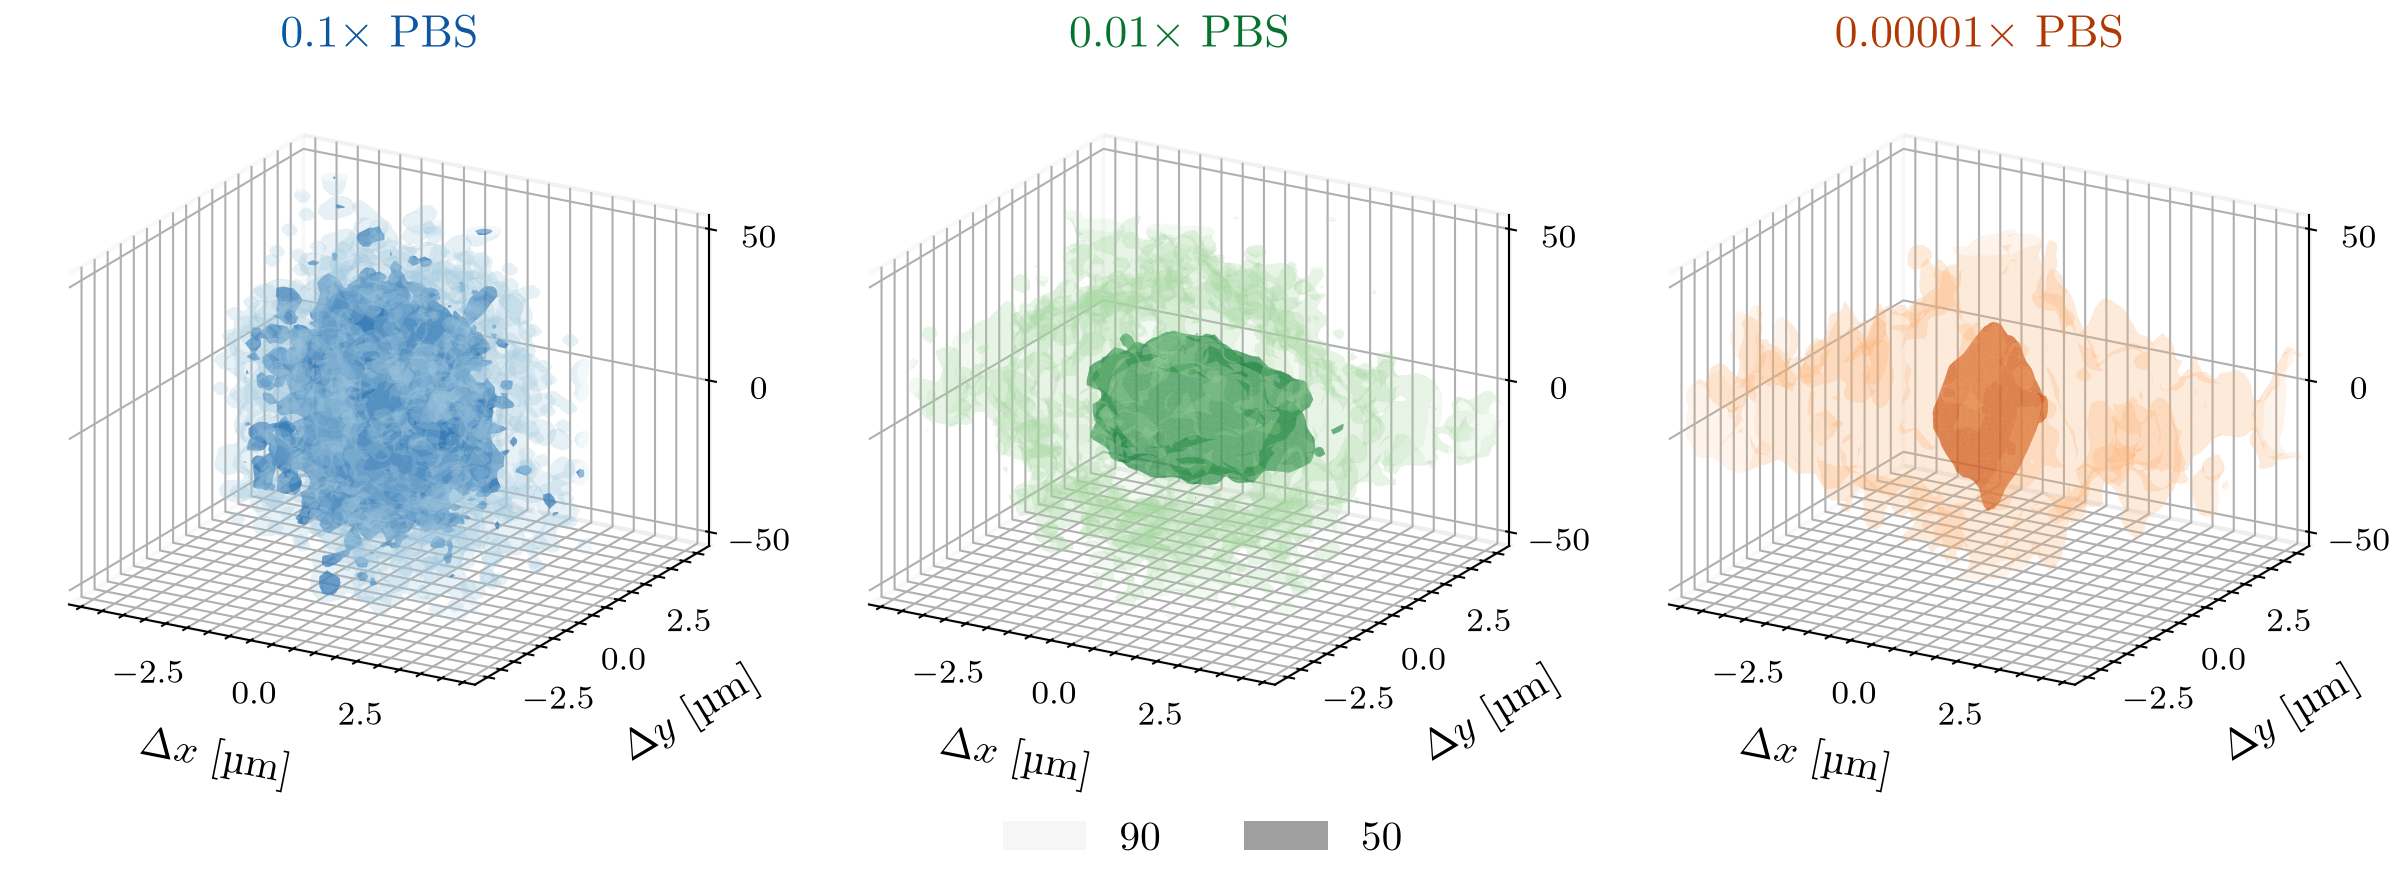

In [68]:
PALETTE = {r'$0.1 \times$ PBS': 'Blues',
           r'$0.01 \times$ PBS': 'Greens',
           r'$0.00001 \times$ PBS': 'Oranges'}      # or explicit ('#a8c8e8', '#1f5fa8') pairs

LEVELS = [(0.90, 0.35, 0.14),                     # (enclosed mass, cmap position, face α)
          (0.50, 0.80, 0.50)]

fig, axes = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True,
                         subplot_kw={'projection': '3d'}, dpi=300)

for ax, (label, (x, y, z, w)) in zip(axes, pooled.items()):
    F, frac = density(x, y, z, w)
    cmap = plt.get_cmap(PALETTE[label])

    for alpha, shade, a in LEVELS:
        if alpha > frac:                          # box too small to contain this level
            print(f'{label}: {alpha:.0%} level clipped (only {frac:.1%} retained)')
            continue
        v, faces, *_ = marching_cubes(F, level=hdr_level(F, alpha / frac),
                                      spacing=(dx, dy, dz))
        ax.add_collection3d(Poly3DCollection(v[faces] + origin,
                                             facecolor=cmap(shade), alpha=a, lw=0))

    ax.set_title(label, color=cmap(0.85), fontsize=11, pad=0)
    ax.set(xlim=xe[[0, -1]], ylim=ye[[0, -1]], zlim=ze[[0, -1]])
    #ax.set_box_aspect((1, 1, 0.85), zoom=1.25)    # camera zoom; trims dead margin
    ax.set_proj_type('ortho')                     # no perspective ⇒ sizes comparable
    ax.view_init(elev=20, azim=-60)
    ax.set_xlabel(r'$\Delta x$ [µm]', labelpad=1)
    ax.set_ylabel(r'$\Delta y$ [µm]', labelpad=1)
    ax.set_zlabel(r'$\Delta z$ [nm]', labelpad=1)
    ax.locator_params(nbins=4)
    ax.tick_params(labelsize=8, pad=-1)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False

fig.legend(handles=[Patch(facecolor=plt.get_cmap('Greys')(s), alpha=a,
                          label=f'{al:.0%} of occupancy') for al, s, a in LEVELS],
           loc='outside lower center', ncol=2, frameon=False)

save_fig(fig, 'Figures/density', also='pdf')


In [ ]:
#RXY_PS100_0p1,      RZ_PS100_0p1        = GetRadius(PS_PBS0p1_225nm    , fps = 400, visc=1*10**(-3)     )
#RXY_PS100_0p01,     RZ_PS100_0p01       = GetRadius(PS_PBS0p01_225nm   , fps = 400, visc=1*10**(-3)     )
#RXY_PS100_0p00001,  RZ_PS100_0p00001    = GetRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3)     )

RXY_PS100_0p1,      FWHM_PS100_0p1       = GetFwhmTransverseRadius(PS_PBS0p1_225nm, fps = 400, visc=1*10**(-3))
RXY_PS100_0p01,     FWHM_PS100_0p01      = GetFwhmTransverseRadius(PS_PBS0p01_225nm, fps = 400, visc=1*10**(-3))
RXY_PS100_0p00001,  FWHM_PS100_0p00001   = GetFwhmTransverseRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3), channel_height=225)



100%|██████████| 62/62 [00:00<00:00, 13468.35it/s]


In [7]:
panel_b_datasets = [PS_PBS0p1_225nm, PS_PBS0p01_225nm, PS_PBS0p001_225nm, PS_PBS0p00001_225nm]
panel_b_labels   = ['0.01x, 225nm', '0.001x, 225nm', '0.00001x, 225nm'  ]

# loop over each dataset
ensemble_hist = []
#ensemble_bins = []
for dataset in panel_b_datasets:
    temp = []
    #bins = []
    # loop over all particles in the set
    for PID in dataset:
        z_of_t = np.array(PID.traj_z)
        z_mean = np.mean(PID.traj_z, axis=0)
        #H, bin = np.histogram(z_of_t - z_mean, 50, [-100, 100], density=True)
        temp.append(z_of_t - z_mean)
        #bins.append(bin)
    # append to ensemble
    ensemble_hist.append(temp)
    #ensemble_bins.append(bins)


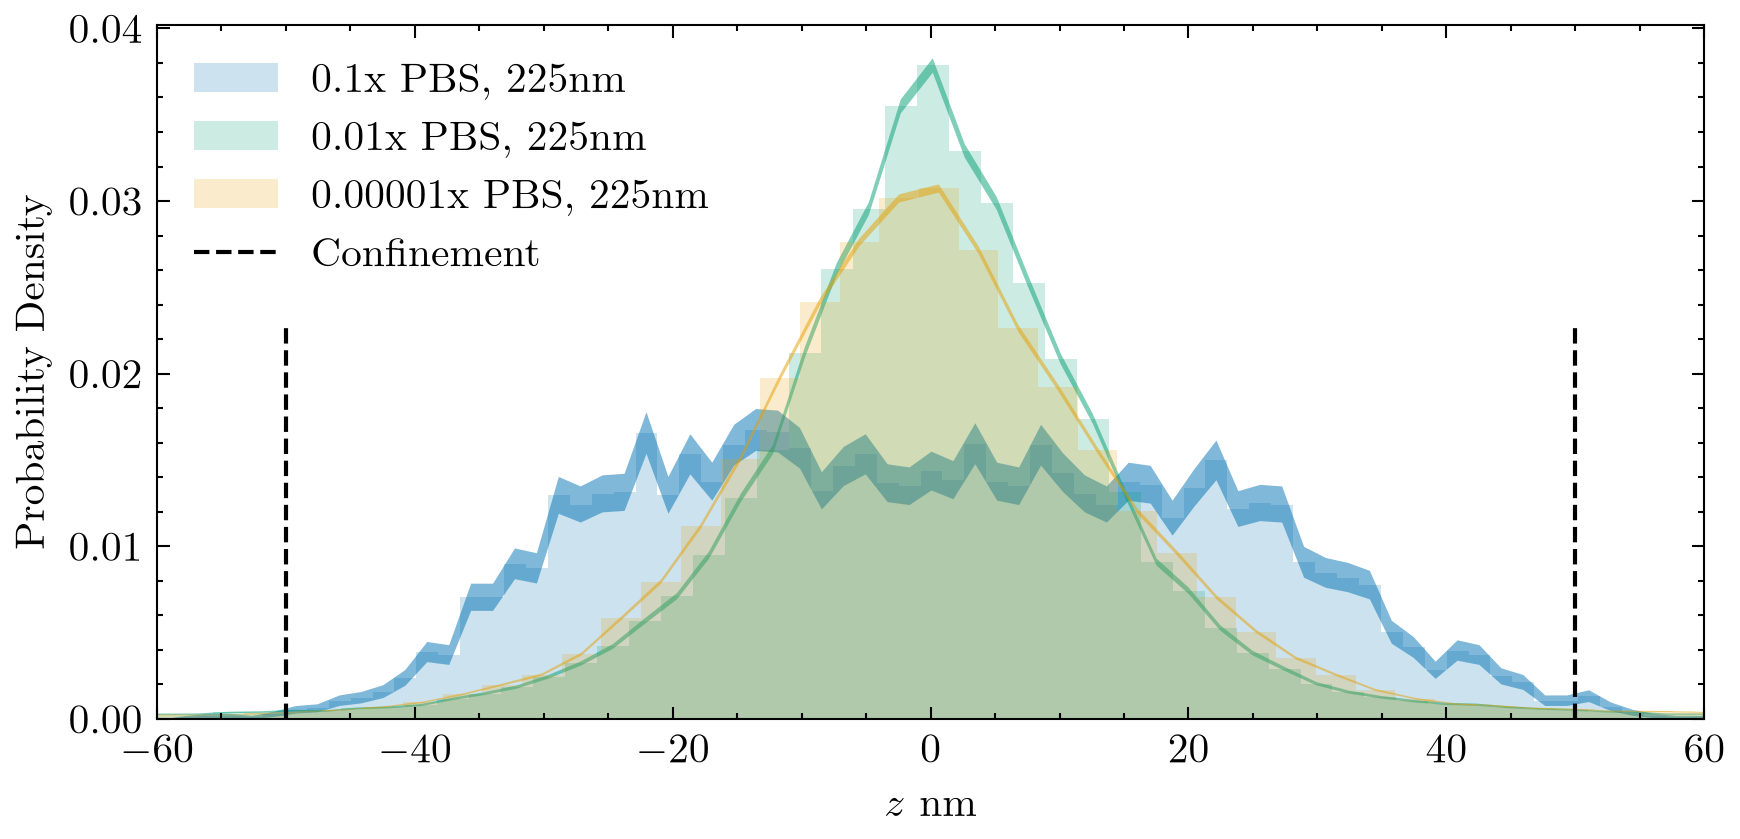

WindowsPath('Figures/Chapter7/c7_fig3.svg')

In [26]:
len_dataset = len(panel_b_datasets)


# construct figure body
fig = plt.figure(figsize=(6,3))
ax = fig.add_subplot()

PBS0p1_zdata         = np.concatenate(ensemble_hist[0], axis=0)
PBS0p01_zdata        = np.concatenate(ensemble_hist[1], axis=0)
PBS0p001_zdata       = np.concatenate(ensemble_hist[2], axis=0)
PBS0p00001_zdata     = np.concatenate(ensemble_hist[3], axis=0)


def PlotHistogram(data, ax0, label):
    counts, bins, _ = ax0.hist(data,   bins=100,  density=True, alpha=0.2, label=label)
    centers  = (bins[:-1] + bins[1:])/2
    dx = np.diff(bins)
    N = len(data)
    std = np.sqrt(counts / (N * dx))
    ax.fill_between(centers , counts-std, counts+std, alpha=0.5)

    return counts, bins

counts_all = []


c1, b1 = PlotHistogram(PBS0p1_zdata,        ax, '0.1x  PBS, 225nm')
c2, b2 = PlotHistogram(PBS0p01_zdata,       ax, '0.01x  PBS, 225nm')
c4, b4 = PlotHistogram(PBS0p00001_zdata,    ax, '0.00001x  PBS, 225nm')

# counting
counts_all.append(c1)
counts_all.append(c2)
counts_all.append(c4)
max_y = np.array(counts_all).max()
ax.vlines(100- 50,  0, max_y - 0.015, 'black', 'dashed')
ax.vlines(-100+ 50, 0, max_y - 0.015, 'black', 'dashed', label='Confinement')
ax.set_xlim(-110 + 50, 110 - 50)

ax.set_xlabel(r'$z$ nm')
ax.set_ylabel(r'Probability Density')

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


save_fig(fig, 'Figures/Chapter7/c7_fig3', also='pdf')


Diffusion self-consistn

In [71]:
def linear(x, a, b):
    return a * x + b

def getDiffusionMSD(trajectory, pixel_size, exposure_time, max_time=3, plotting=0, xmin = 0, xmax=100, dpi_set=200):
    trajectory_meters = trajectory
    msd, lag, ndim = getMeanSquaredDisplacement(trajectory_meters)
    time_s = exposure_time * lag
    msd_m2 = msd * pixel_size**2

    # MSD diffusion
    from scipy.optimize import curve_fit
    popt, cov = curve_fit(linear, time_s[:max_time], msd_m2[:max_time]) # m^2/s
    D = popt[0]
    alpha = popt[1]

    # optional plotting
    if plotting == 1:
        plt.figure(11, dpi=dpi_set)
        plt.plot(time_s[xmin:xmax], msd_m2[xmin:xmax], label='MSD')
        plt.plot(time_s[xmin:xmax], linear(time_s, *popt)[xmin:xmax], label='Linear Fit')
        plt.legend()
        plt.show(block=False)

    return (D/(2 * ndim), alpha)

In [81]:
# get a single trajectory

ds = PS_PBS0p1_225nm[1]
trajx_single = [ds.traj_x]
trajy_single = [ds.traj_y] 


In [110]:
fps = 300
px_size = 55 * 10**(-9)
channel_height = 225
visc = 1.006 * 10**(-3)
distance_thresh = 1* 10**(-6)
hat_r = np.arange(1, channel_height, 0.1) # 0.1 nm steps

Dif_lnp_PBS = []
Sig_lnp_PBS = []
Rad_lnp_PBS = []

kb = 1.380649 * 10**(-23)

 # good entries
good_lnp_PBS = np.arange(len(trajx_single))
bad_lnp_PBS = []

for index, (traj_x_bead_i, traj_y_bead_i) in enumerate(zip(trajx_single, trajy_single)):
    # raw trace of particle
    traj_loop = np.array((traj_x_bead_i, traj_y_bead_i)) * 1/(px_size)

    # filtering of particle
    
    # needs to move at least 1 um
    D_ij = np.subtract.outer(traj_x_bead_i, traj_y_bead_i)
    D_ij = np.abs(D_ij)
    thresh = np.max(D_ij)
    
    if thresh <= distance_thresh:
        bad_lnp_PBS.append(index)

    # compute the diffusivity and radius
    (D_msd, alpha_msd) = getDiffusionMSD(traj_loop, 1, 1/fps, max_time=15, plotting=0, xmin=1, xmax=15, dpi_set=100)
    D_msd_m2 = D_msd * (px_size)**2
    
    Dif_lnp_PBS.append(D_msd)
    Sig_lnp_PBS.append(alpha_msd)

    # estimate r1
    r1 = kb * 293 / (6 * np.pi * visc * D_msd_m2) * 10**(9) # nm

    print(r1)
    #print(1/ConfinementDiffusionCorrection(1, r1, channel_height, 'linsup'))


    # stuck particles have too large size
    if r1 > channel_height: #nm
        bad_lnp_PBS.append(index)


    # make cost vector and ge tbest solution
    cost_vector = np.array([( r1 / ConfinementDiffusionCorrection(1, r_test, channel_height/2, 'linsup') - r_test ) for r_test in hat_r])
    r_true = hat_r[np.argmin(np.abs(cost_vector))]


    #if r_true < 20:
    #    print(index)

    #print(1/ConfinementDiffusionCorrection(1, r_true, channel_height, 'parr'))


    #r2 = argmin__{hat_r}(hat_r ConfinementDiffusionCorrection(1, r1, channel_height, 'parr') - hat_r)
    #D_par = ConfinementDiffusionCorrection(D_msd, r1, channel_height, 'parr')

    #r2 = kb * 293 / (6 * np.pi * 1.006 * 10**(-3)  * D_par) * 10**(9) # nm

    Rad_lnp_PBS.append(r_true)
    

124.30003384680418


WindowsPath('Figures/Mobility_coefficient.svg')

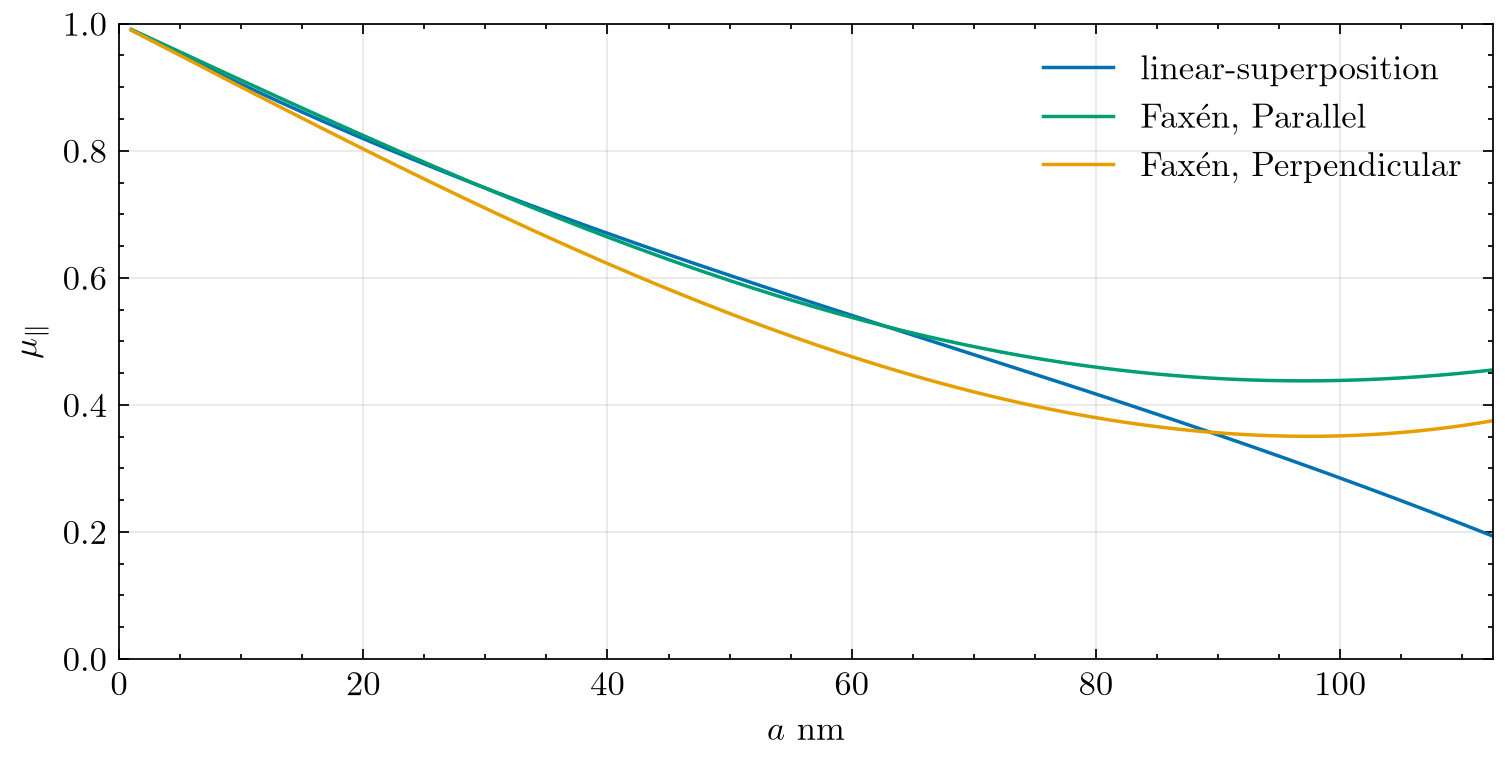

In [143]:
x = hat_r
y = 1/ConfinementDiffusionCorrection(1, hat_r, channel_height/2, 'linsup')
y1 = 1/ConfinementDiffusionCorrection(1, hat_r, channel_height/2, 'parr' )
y2 = 1/ConfinementDiffusionCorrection(1, hat_r, channel_height/2, 'perp' )


fig, ax = plt.subplots(1,1,dpi = 250)
ax.plot(x,y , label='linear-superposition')
ax.plot(x,y1, label='Faxén, Parallel')
ax.plot(x,y2, label='Faxén, Perpendicular')

ax.set_xlim(0, channel_height/2)
ax.set_ylim(0, 1)

ax.set_ylabel(r'$\mu_\parallel$')
ax.set_xlabel(r'$a$ nm')
ax.grid(alpha=0.3)
#fig:mob_coef
ax.legend()
save_fig(fig, 'Figures/Mobility_coefficient', also='pdf')


[np.float64(64.10000000000005)]


WindowsPath('Figures/diffusion_self_consistent_example.svg')

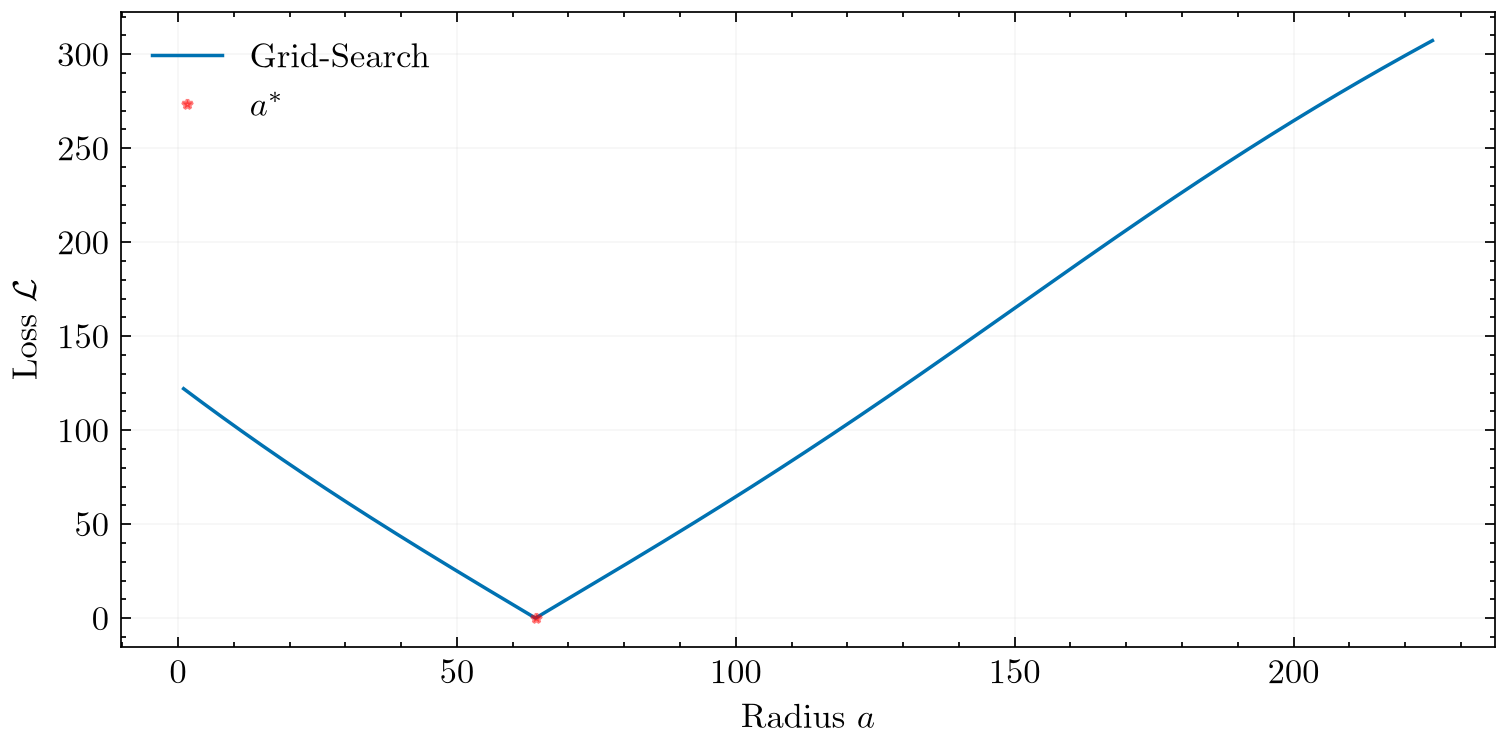

In [111]:
print(Rad_lnp_PBS)

fig, ax = plt.subplots(1,1, dpi=250)

ax.plot(hat_r, np.abs(cost_vector), label='Grid-Search')
ax.set_xlabel(rf'Radius $a$')
ax.set_ylabel(r'Loss $\mathcal{L}$')
ax.plot(r_true, np.min(np.abs(cost_vector)), 'r*', alpha=0.5, ms=3, label =r'$a^*$')
ax.grid(alpha=0.1)
ax.legend()
save_fig(fig, 'Figures/diffusion_self_consistent_example', also='pdf')

# Radius 

In [159]:
#RXY_PS100_0p1,      RZ_PS100_0p1        = GetRadius(PS_PBS0p1_225nm    , fps = 400, visc=1*10**(-3)     )
#RXY_PS100_0p01,     RZ_PS100_0p01       = GetRadius(PS_PBS0p01_225nm   , fps = 400, visc=1*10**(-3)     )
#RXY_PS100_0p00001,  RZ_PS100_0p00001    = GetRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3)     )

RXY_PS100_0p1,      FWHM_PS100_0p1       = GetFwhmTransverseRadius(PS_PBS0p1_225nm, fps = 400, visc=1*10**(-3))
RXY_PS100_0p01,     FWHM_PS100_0p01      = GetFwhmTransverseRadius(PS_PBS0p01_225nm, fps = 400, visc=1*10**(-3))
RXY_PS100_0p00001,  FWHM_PS100_0p00001   = GetFwhmTransverseRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3), channel_height=225, distance_thresh=1e-6)



100%|██████████| 62/62 [00:00<00:00, 15451.39it/s]


WindowsPath('Figures/FWHM_PBS.svg')

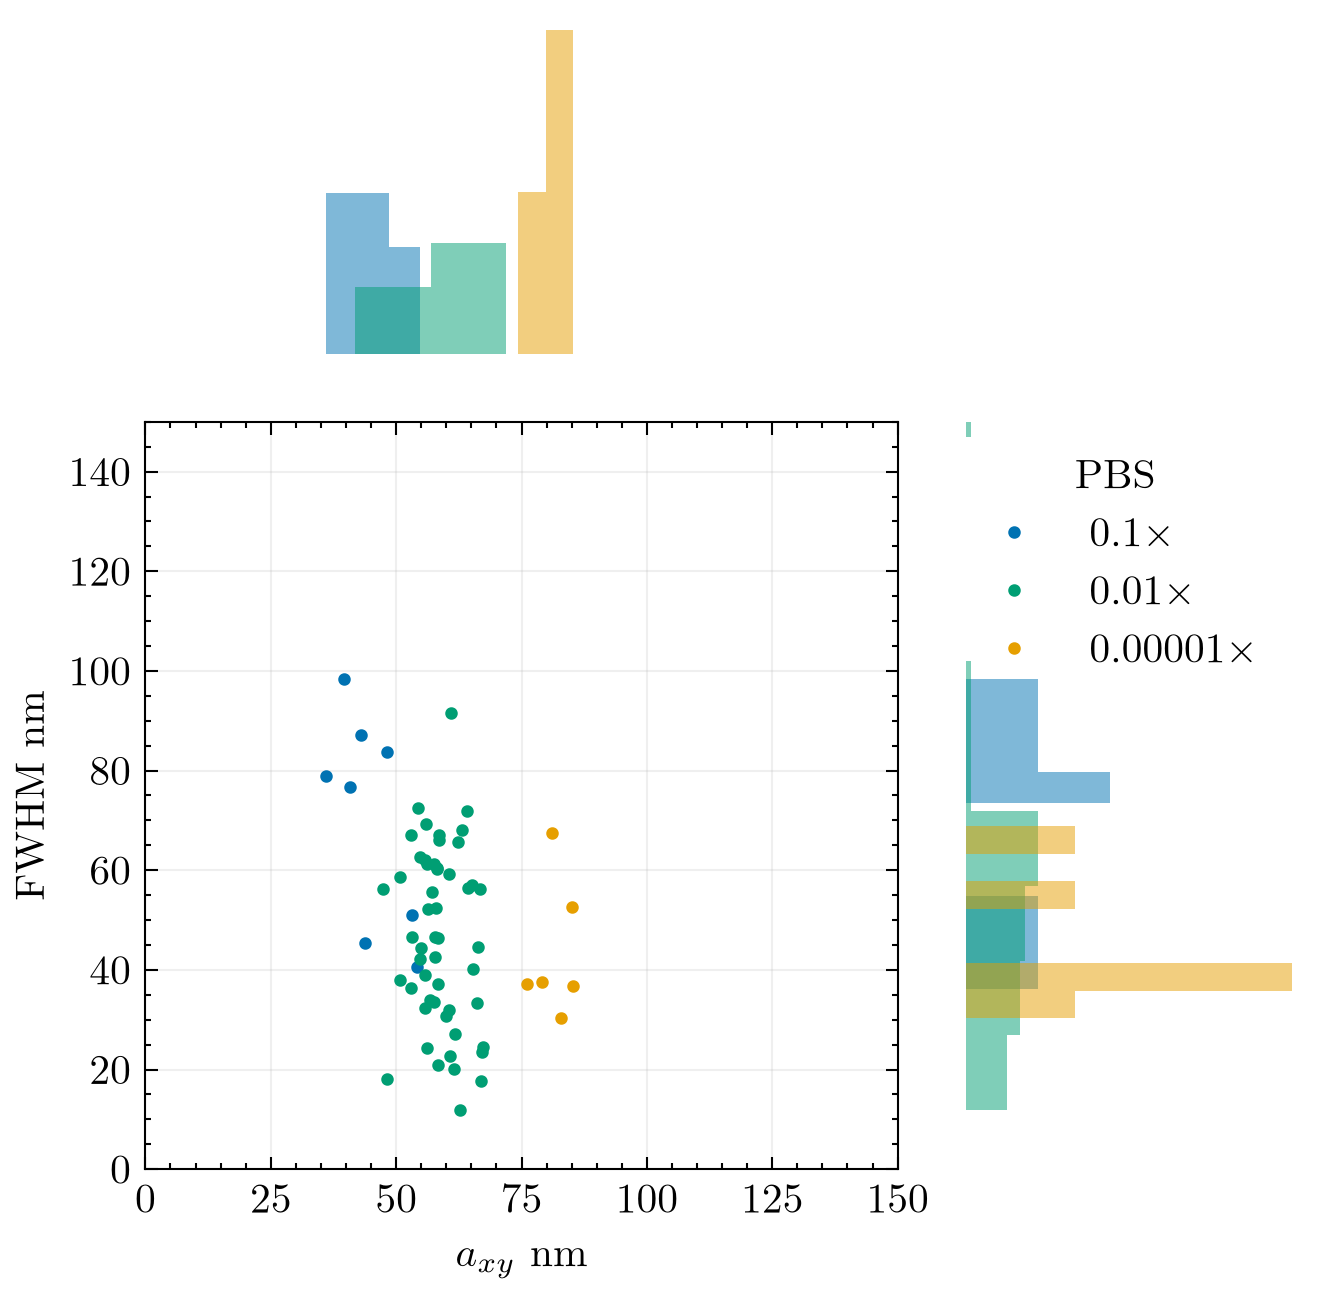

In [169]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(5,
                          5), dpi=300)
gs = gridspec.GridSpec(3, 3)
ax2 = plt.subplot(gs[1:3, :2])
ax11 = plt.subplot(gs[0, :2] , sharex = ax2)
ax12 = plt.subplot(gs[1:3, 2], sharey = ax2)
ax11.set_axis_off()
ax12.set_axis_off()

plt.setp(ax11.get_xticklabels(), visible=False)
plt.setp(ax11.get_yticklabels(), visible=False)

plt.setp(ax12.get_xticklabels(), visible=False)
plt.setp(ax12.get_yticklabels(), visible=False)

#ax2.plot(np.arange(0, 200), np.arange(0, 200), 'k--', alpha=0.3)


# ------------------------------------------------------------
# DATA SETTINGS
# ------------------------------------------------------------

def PlotRadius(RadX, RadZ, axmain, axtop, axbot, color, label):
    all_data = np.concatenate([RadX, RadZ])
    bins = np.histogram_bin_edges(all_data, bins=10)

    axmain.plot(RadX, RadZ, color=color, marker='o', linestyle='', ms=2, label=label)
    axtop.hist(RadZ, orientation='horizontal', bins=bins, color=color, alpha=0.5, density = True)
    axbot.hist(RadX,bins=bins,color=color,alpha=0.5, density = True)   

#PlotRadius(RXY_PS100_0p1, RZ_PS100_0p1, ax2, ax12, ax11, 'purple')
#PlotRadius(RXY_PS100_0p01, RZ_PS100_0p01, ax2, ax12, ax11, 'green')
#PlotRadius(RXY_PS100_0p00001, RZ_PS100_0p00001, ax2, ax12, ax11, 'blue')

PlotRadius(RXY_PS100_0p1,     FWHM_PS100_0p1, ax2, ax12, ax11, color='#0072B2',    label=r'$0.1 \times$ ' )
PlotRadius(RXY_PS100_0p01,    FWHM_PS100_0p01, ax2, ax12, ax11, color='#009E73',   label=r'$0.01 \times$ ')
PlotRadius(RXY_PS100_0p00001, FWHM_PS100_0p00001, ax2, ax12, ax11, color='#E69F00',label=r'$0.00001 \times$ ')



# ------------------------------------------------------------
# DATA SETTINGS
# ------------------------------------------------------------



#ax2.set_ylabel(r'$r_{z} [nm]$')
ax2.set_ylabel(r'FWHM nm')
ax2.set_xlabel(r'$a_{xy}$ nm')
ax2.set_xlim(0, 150)
ax2.set_ylim(0, 150)
ax2.grid(alpha=0.2)
ax11.grid(alpha=0.2)
ax12.grid(alpha=0.2)
ax2.legend(title="PBS", bbox_to_anchor=(1.05, 1), loc='upper left')

save_fig(fig, 'Figures/FWHM_PBS', also='pdf')

In [170]:
RXY_PS100_0p1,      RZ_PS100_0p1        = GetRadius(PS_PBS0p1_225nm    , fps = 400, visc=1*10**(-3)     )
RXY_PS100_0p01,     RZ_PS100_0p01       = GetRadius(PS_PBS0p01_225nm   , fps = 400, visc=1*10**(-3)     )
RXY_PS100_0p00001,  RZ_PS100_0p00001    = GetRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3)     )




100%|██████████| 62/62 [00:25<00:00,  2.41it/s]


WindowsPath('Figures/RadxvsRadz_PBS.svg')

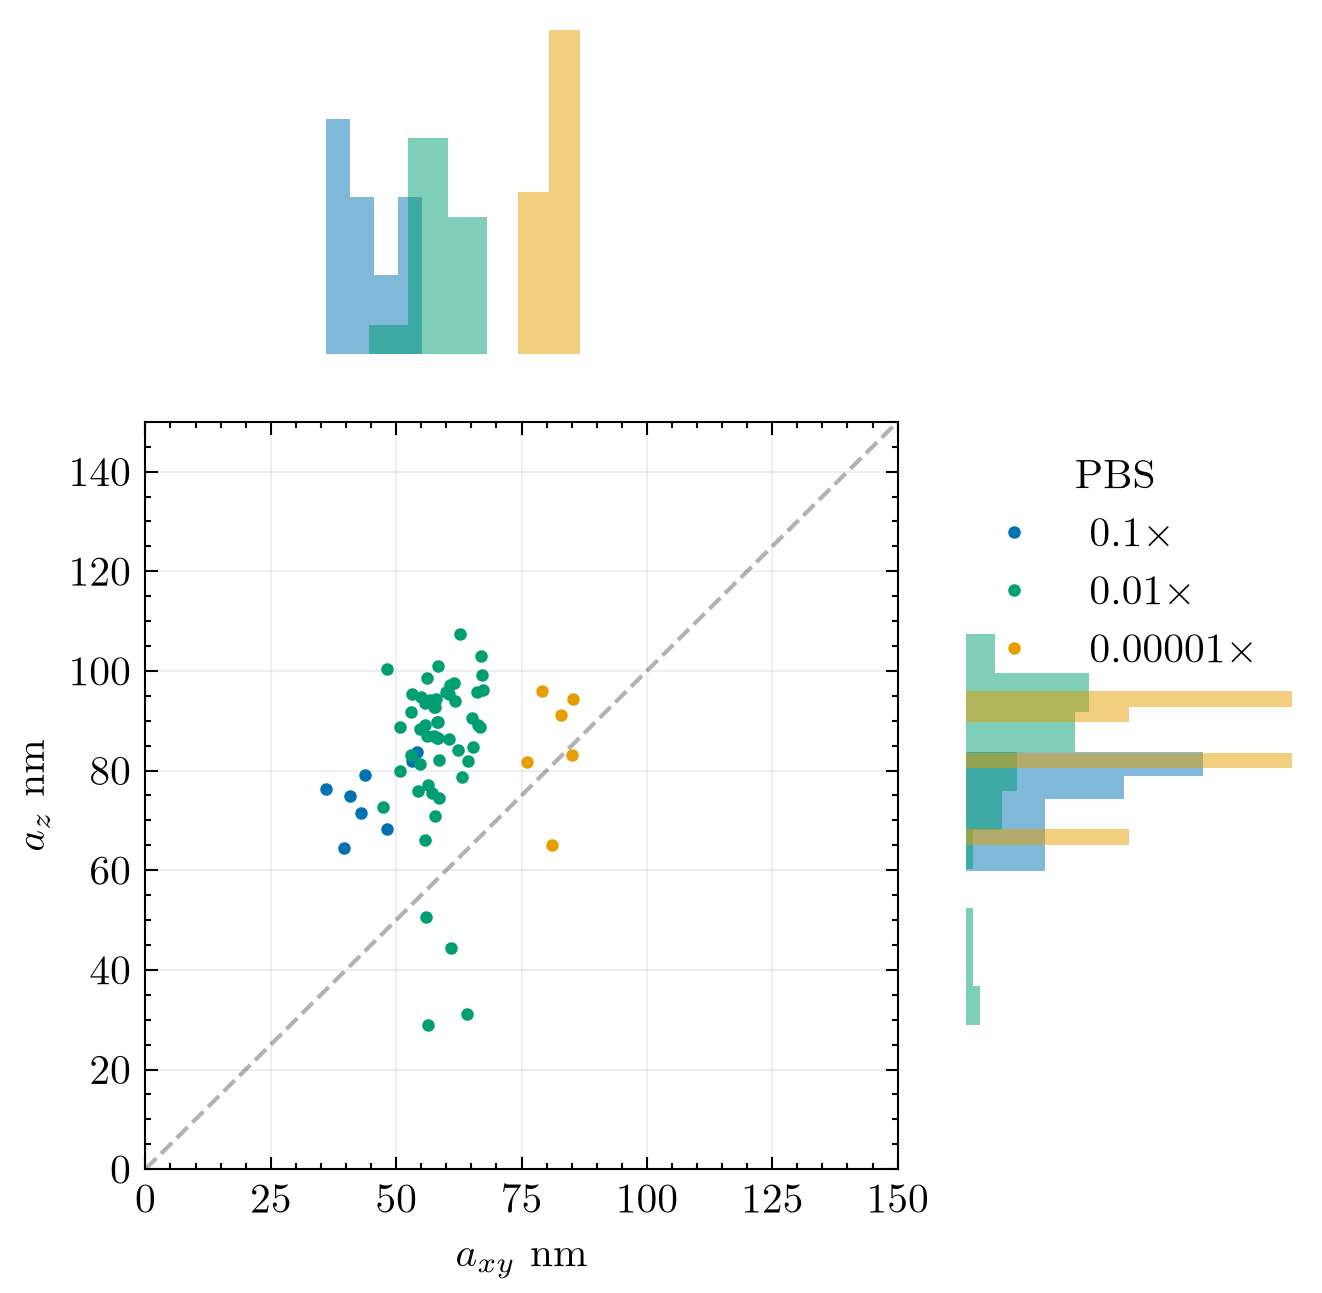

In [174]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(5,
                          5), dpi=300)
gs = gridspec.GridSpec(3, 3)
ax2 = plt.subplot(gs[1:3, :2])
ax11 = plt.subplot(gs[0, :2] , sharex = ax2)
ax12 = plt.subplot(gs[1:3, 2], sharey = ax2)
ax11.set_axis_off()
ax12.set_axis_off()

plt.setp(ax11.get_xticklabels(), visible=False)
plt.setp(ax11.get_yticklabels(), visible=False)

plt.setp(ax12.get_xticklabels(), visible=False)
plt.setp(ax12.get_yticklabels(), visible=False)

ax2.plot(np.arange(0, 200), np.arange(0, 200), 'k--', alpha=0.3)


# ------------------------------------------------------------
# DATA SETTINGS
# ------------------------------------------------------------

def PlotRadius(RadX, RadZ, axmain, axtop, axbot, color, label):
    all_data = np.concatenate([RadX, RadZ])
    bins = np.histogram_bin_edges(all_data, bins=10)

    axmain.plot(RadX, RadZ, color=color, marker='o', linestyle='', ms=2, label=label)
    axtop.hist(RadZ, orientation='horizontal', bins=bins, color=color, alpha=0.5, density = True)
    axbot.hist(RadX,bins=bins,color=color,alpha=0.5, density = True)   

#PlotRadius(RXY_PS100_0p1, RZ_PS100_0p1, ax2, ax12, ax11, 'purple')
#PlotRadius(RXY_PS100_0p01, RZ_PS100_0p01, ax2, ax12, ax11, 'green')
#PlotRadius(RXY_PS100_0p00001, RZ_PS100_0p00001, ax2, ax12, ax11, 'blue')

PlotRadius(RXY_PS100_0p1,     RZ_PS100_0p1, ax2, ax12, ax11, color='#0072B2',    label=r'$0.1 \times$ ' )
PlotRadius(RXY_PS100_0p01,    RZ_PS100_0p01, ax2, ax12, ax11, color='#009E73',   label=r'$0.01 \times$ ')
PlotRadius(RXY_PS100_0p00001, RZ_PS100_0p00001, ax2, ax12, ax11, color='#E69F00',label=r'$0.00001 \times$ ')



# ------------------------------------------------------------
# DATA SETTINGS
# ------------------------------------------------------------



#ax2.set_ylabel(r'$r_{z} [nm]$')
ax2.set_ylabel(r'$a_{z}$ nm')
ax2.set_xlabel(r'$a_{xy}$ nm')
ax2.set_xlim(0, 150)
ax2.set_ylim(0, 150)
ax2.grid(alpha=0.2)
ax11.grid(alpha=0.2)
ax12.grid(alpha=0.2)
ax2.legend(title="PBS", bbox_to_anchor=(1.05, 1), loc='upper left')

save_fig(fig, 'Figures/RadxvsRadz_PBS', also='pdf')

# Transient Diffusion Information

In [175]:
# List of Datasets For Figure 1
# Polystyrene + PBS
#PS_PBS1_GLY45p_225nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft2\ClicOnLeft2radial_int_50_to_359ws_8_we_26_PythonAnalysis.h5")#"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_45p\ClicOnLeft2\mj_iSCAT_100nmPS_75p_1xPBS_1ms_exp_900mW_CLiConLeft_Pinhole_2ndmax_f2radial_int_0_to_80ws_8_we_26_PythonAnalysis.h5")
PS_PBS1_GLY45p_225nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft2\ClicOnLeft2radial_int_50_to_359ws_8_we_26maxstep5nm_PythonAnalysis.h5")#"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_45p\ClicOnLeft2\mj_iSCAT_100nmPS_75p_1xPBS_1ms_exp_900mW_CLiConLeft_Pinhole_2ndmax_f2radial_int_0_to_80ws_8_we_26_PythonAnalysis.h5")


#PS_PBS1_GLY45p_300nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_45p\ClicOnLeft3\mj_iSCAT_100nmPS_75p_1xPBS_1ms_exp_900mW_CLiConLeft_Pinhole_2ndmax_f3radial_int_0_to_80ws_8_we_26_PythonAnalysis.h5")

Particles in Current Dataset: 7


In [176]:
panel_a_datasets = [PS_PBS1_GLY45p_225nm]#, PS_PBS1_GLY45p_300nm]

# loop over each dataset
x_trajectories = []
y_trajectories = []
z_trajectories = []

for dataset in panel_a_datasets:
    temp = []
    #bins = []
    # loop over all particles in the set
    for PID in dataset:
        x_trajectories.append(np.array(PID.traj_x))
        y_trajectories.append(np.array(PID.traj_y))
        z_trajectories.append(np.array(PID.traj_z))
        

print(f'{len(x_trajectories)} particles loaded.')

7 particles loaded.


msd distribution

In [179]:
from hdr.transverse_estimation import getMeanSquaredDisplacement

def GetStuffFast(index):
    # assemble trajectory vectors
    xy_traj = np.array([x_trajectories[index], y_trajectories[index]]) * 1/(10**(-9))         # nm
    z_traj =  np.reshape(np.array([z_trajectories[index]]), (1, len(z_trajectories[index])))  # nm

    return xy_traj, z_traj


xy_msds = []
z_msds = []
t_xys = []
t_zs = []

for index in range(len(x_trajectories)):
    # assemble trajectory vectors
    xy_traj = np.array([x_trajectories[index], y_trajectories[index]]) * 1/(10**(-9))         # nm
    z_traj =  np.reshape(np.array([z_trajectories[index]]), (1, len(z_trajectories[index])))  # nm

    # Calculate the MSD

    t_MSD, t_lag, t_ndim = getMeanSquaredDisplacement(xy_traj) 
    xy_msds.append(t_MSD)
    t_xys.append(t_lag)
    z_MSD, z_lag, z_ndim = getMeanSquaredDisplacement(z_traj)
    z_msds.append(z_MSD)
    t_zs.append(z_lag)

WindowsPath('Figures/glycerol_MSD.svg')

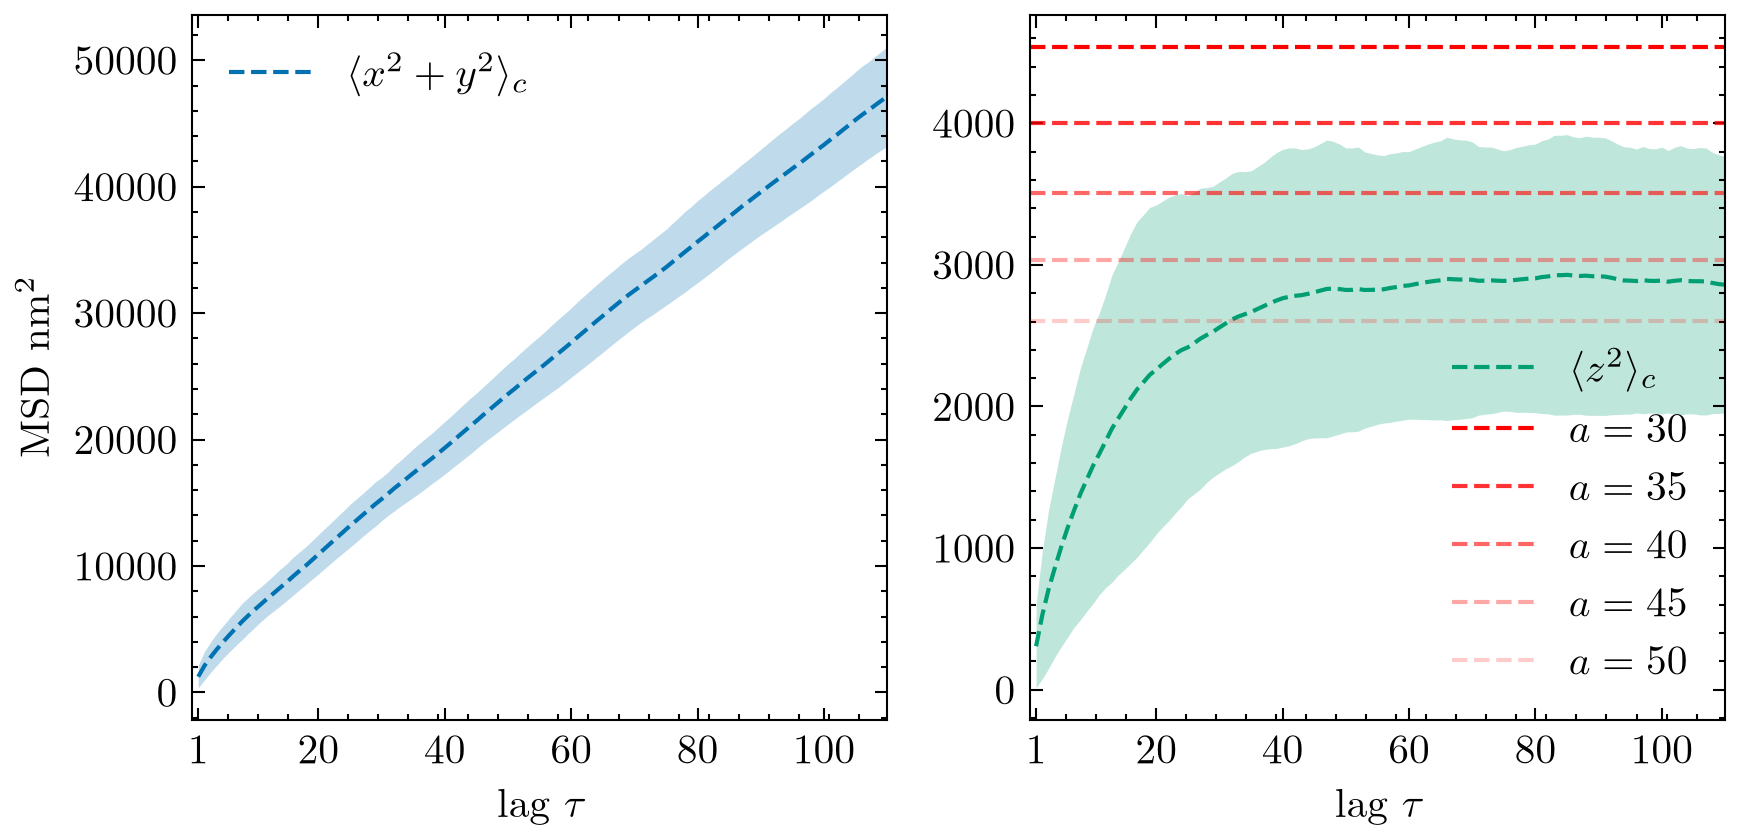

In [222]:
end_t = 110

def pad(arrs):
    F = max(len(a) for a in arrs)
    A = np.full((len(arrs), F), np.nan)
    for i, a in enumerate(arrs):
        A[i, :len(a)] = a
    return A

xy = pad(xy_msds)
z  = pad(z_msds)
xlag = max(t_xys, key=len)
zlag = max(t_zs,  key=len)

fig, (ax1, ax2) = plt.subplots(1, 2, dpi=300, figsize= (6, 3))

for lag, M, c, lab in [(xlag, xy, 'C0', r'$\langle x^2 + y^2\rangle_c$')]:
    mu = np.nanmean(M, 0)[:end_t]
    sd = np.nanstd(M, 0)[:end_t]
    t  = np.asarray(lag)[:end_t]
    ax1.plot(t, mu, linestyle='dashed', color=c, label=lab)
    ax1.fill_between(t, mu - sd, mu + sd, color=c, alpha=0.25, lw=0)

for lag, M, c, lab in [(zlag, z, 'C1', r'$\langle z^2 \rangle_c$')]:
    mu = np.nanmean(M, 0)[:end_t]
    sd = np.nanstd(M, 0)[:end_t]
    t  = np.asarray(lag)[:end_t]
    ax2.plot(t, mu, linestyle='dashed', color=c, label=lab)
    ax2.fill_between(t, mu - sd, mu + sd, color=c, alpha=0.25, lw=0)

ax1.set_xticks([1, 20, 40, 60, 80, 100])
ax1.set_xlabel(r'lag $\tau$')
ax1.set_ylabel(r'MSD nm$^2$')
ax1.legend()
ax1.set_xlim(0, 110)

ax2.plot(np.linspace(0, 120, 120), np.ones(120) * (225-60)**2/6,  '--',color='red',alpha=1, label=r'$a = 30$')
ax2.plot(np.linspace(0, 120, 120), np.ones(120) * (225-70)**2/6,  '--',color='red',alpha=0.8, label=r'$a = 35$')

ax2.plot(np.linspace(0, 120, 120), np.ones(120) * (225-80)**2/6,  '--',color='red',alpha=0.6, label=r'$a = 40$')
ax2.plot(np.linspace(0, 120, 120), np.ones(120) * (225-90)**2/6,  '--',color='red',alpha=0.35, label=r'$a = 45$')
ax2.plot(np.linspace(0, 120, 120), np.ones(120) * (225-100)**2/6, '--',color='red',alpha=0.2, label=r'$a = 50$')

ax2.set_xticks([1, 20, 40, 60, 80, 100])
ax2.set_xlabel(r'lag $\tau$')
ax2.legend()
ax2.set_xlim(0, 110)
plt.tight_layout()
save_fig(fig, 'Figures/glycerol_MSD', also='pdf')

#transient across chamber

In [280]:
def SegmentArr1ByArr2_EO(arr1, arr2, bins=400):
    kk = 1
    # fetch arrays
    tx = arr1[0][:-kk] - arr1[0][kk:]
    ty = arr1[1][:-kk] - arr1[1][kk:]
    tz = arr2[0][:-kk] - arr2[0][kk:]

    z_value_temp = (arr2[0][:-kk] + arr2[0][kk:])/2

    # sort trajectory points
    ind_sort = np.argsort(z_value_temp)
    z_value_temp_sort = z_value_temp[ind_sort]

    # get sorted trajectory points
    tmp_v = (np.abs(tx)**2 + np.abs(ty)**2)[ind_sort]
    tmp_z = (np.abs(tz)**2)[ind_sort]

    step = bins
    n = len(tmp_v) // step
    
    z_mean_save         = np.zeros(n)
    diff_save           = np.zeros(n)
    z_std_save          = np.zeros(n)
    diff_save_std       = np.zeros(n)
    z_diff_vec_save     = np.zeros(n)
    z_diff_vec_std_save = np.zeros(n)

    thres = 20

    for ll in range(n):
        # get slice
        sl = slice(ll * step, (ll + 1) * step)
        
        z_test_vec = z_value_temp_sort[sl] - np.median(z_value_temp_sort)
        
        test_test = tmp_v[sl]
        z_diff_small_abs = tmp_z[sl]

        m = z_diff_small_abs < thres ** 2
        w = np.sqrt(np.sum(test_test[m]))

        z_diff_vec_save[ll]         = np.mean(z_diff_small_abs[m])
        z_diff_vec_std_save[ll]     = np.std(z_diff_small_abs[m], ddof=1) / w
        diff_save[ll]               = np.mean(test_test[m])
        diff_save_std[ll]           = np.std(test_test[m], ddof=1) / w
        z_mean_save[ll]             = np.mean(z_test_vec[m])
        z_std_save[ll]              = np.std(z_test_vec[m], ddof=1)

    xc = diff_save / np.max(diff_save) * 1.1
    xerr = diff_save_std / (len(diff_save)**2) * 1.1

    zc = z_diff_vec_save  / np.max(z_diff_vec_save) * 1.1
    zerr = z_diff_vec_std_save / (len(z_diff_vec_save)) * 1.1
    
    return xc, xerr, zc, zerr, z_mean_save, z_std_save


In [281]:
a1 = []
a2 = []
b1 = []
b2 = []
zms = []
zss = []

for index in range(len(x_trajectories)):
    # assemble trajectory vectors
    xy_traj = np.array([x_trajectories[index], y_trajectories[index]]) * 1/(10**(-9))         # nm
    z_traj =  np.reshape(np.array([z_trajectories[index]]), (1, len(z_trajectories[index])))  # nm

    xc, xerr, zc, zerr, z_mean_save, z_std_save = SegmentArr1ByArr2_EO(xy_traj, z_traj, 400)

    a1.append(xc)
    a2.append(xerr)
    b1.append(zc)
    b2.append(zerr)
    zms.append(z_mean_save)
    zss.append(z_std_save)

In [ ]:
a       = 50 # nm
h       = 225 # nm
peg     = 0
z_vec   = np.linspace(a+peg, h - a - peg, 400)

ratio_a_z1   = a/(z_vec)
ratio_a_z2   = a/(h - z_vec)

# parallel motion
mob1 = (1 - 9/16 * ratio_a_z1 + 1/8 * ratio_a_z1**3 - 45/256 * ratio_a_z1**4 - 1/16 * ratio_a_z1**5)
mob2 = (1 - 9/16 * ratio_a_z2 + 1/8 * ratio_a_z2**3 - 45/256 * ratio_a_z2**4 - 1/16 * ratio_a_z2**5)
mob_tot_parr = 1/(1/mob1 + 1/mob2 - 1)

# perpendicular motion
mob1 = (6- 10 * ratio_a_z1 + 4 * ratio_a_z1**2)/(6 - 3 * ratio_a_z1 - ratio_a_z1**2)
mob2 = (6- 10 * ratio_a_z2 + 4 * ratio_a_z2**2)/(6 - 3 * ratio_a_z2 - ratio_a_z2**2)
mob_tot_perp = 1/(1/(mob1 + 1e-20) + 1/(mob2 + 1e-20) - 1)


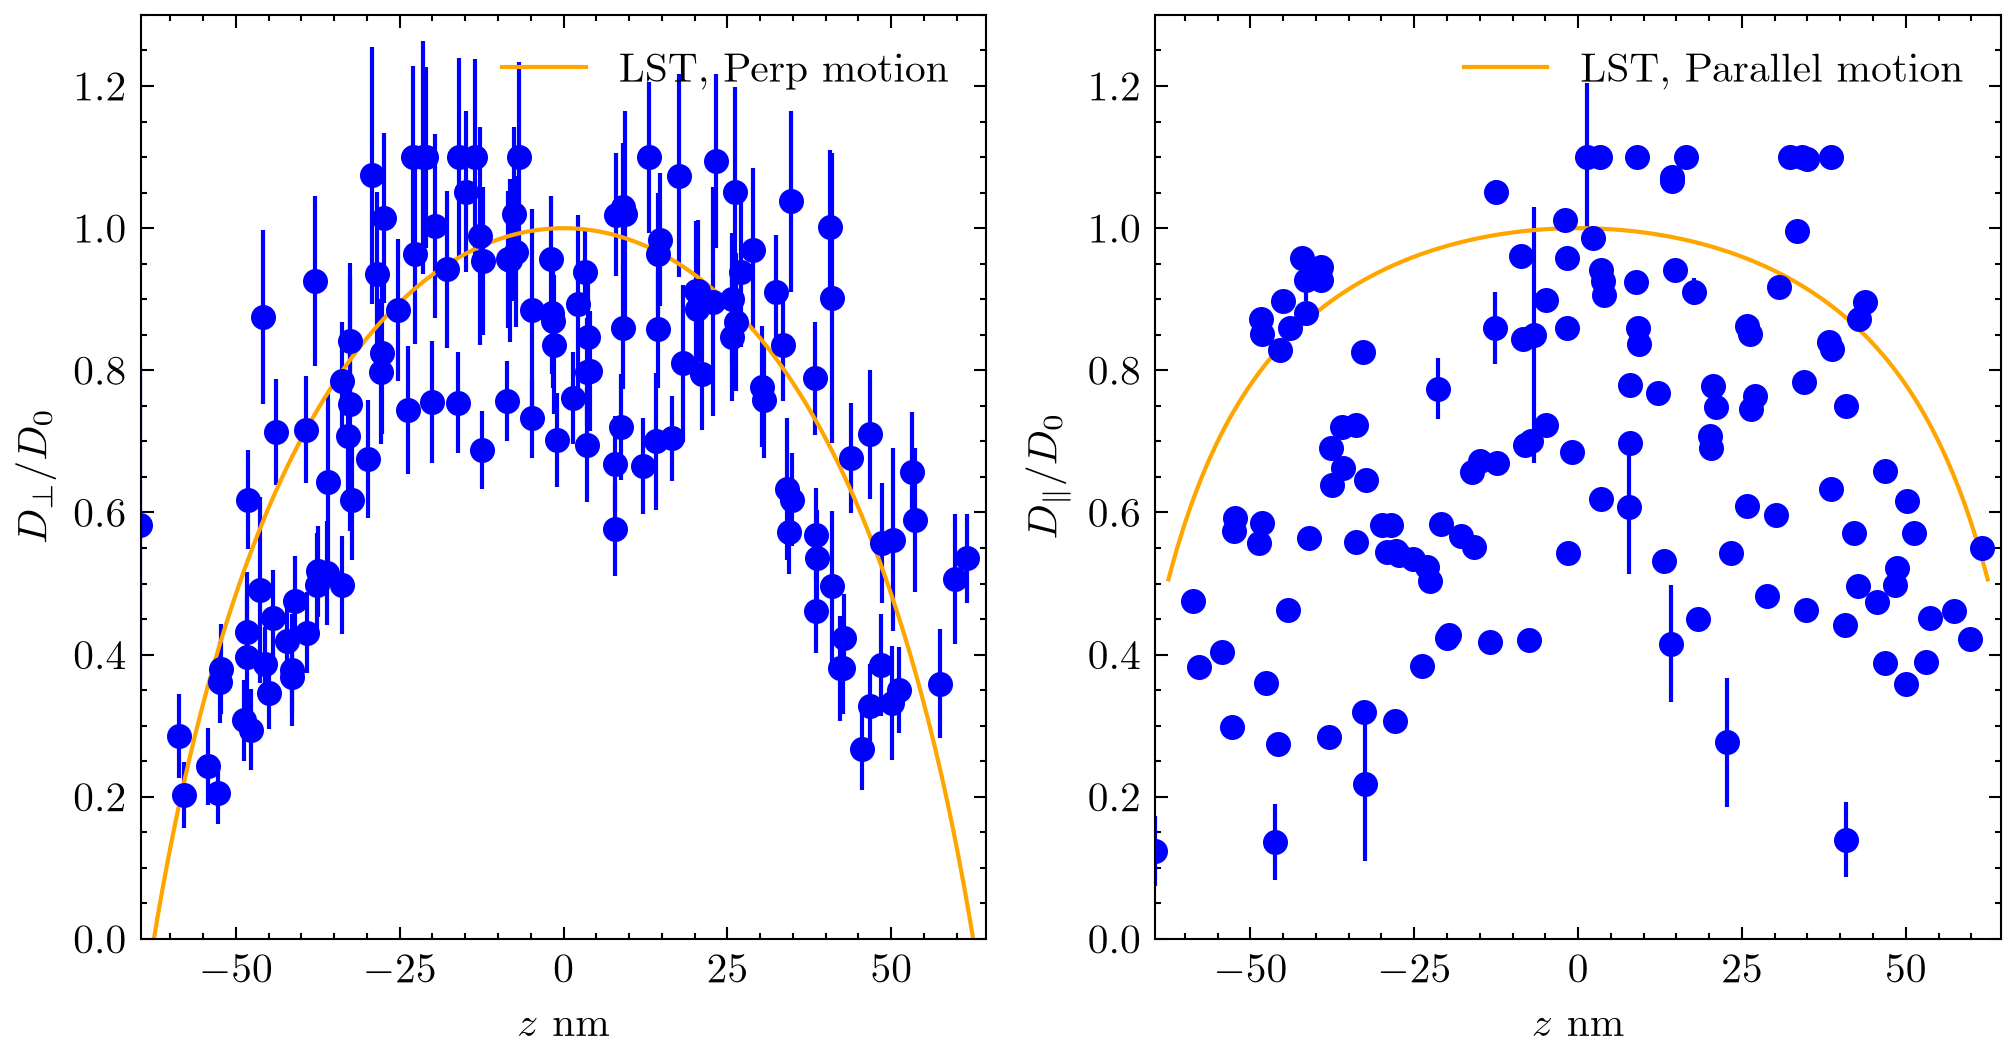

In [290]:

fig1, (ax1, ax2) = plt.subplots(1,2, figsize=(8,4))

# Data Lines
for i in range(7):
    ax1.errorbar(zms[i], (b1[i]), yerr=10 *b2[i], linestyle='', color='blue',marker='o', markersize=5)
    ax2.errorbar(zms[i], (a1[i]), yerr=a2[i], linestyle='', color='blue',marker='o', markersize=5)


ax1.plot(z_vec - h/2, mob_tot_perp/np.max(mob_tot_perp), color='orange',label='LST, Perp motion')

ax2.plot(z_vec - h/2, mob_tot_parr/np.max(mob_tot_parr), color='orange', label='LST, Parallel motion')

ax1.legend()
ax2.legend()

ax1.set_ylim(0, 1.3)
ax2.set_ylim(0, 1.3)

ax1.set_xlim(-h/2 + a - 2, h/2 - a + 2)
ax2.set_xlim(-h/2 + a - 2, h/2 - a + 2)

ax1.set_xlabel(r'$z$ nm')
ax2.set_xlabel(r'$z$ nm')

ax1.set_ylabel(r'$D_\perp/D_0$')
ax2.set_ylabel(r'$D_\parallel/D_0$')


#fig1.savefig('3panelA.svg')
#fig2.savefig('3panelB.svg')

plt.show()

WindowsPath('Figures/glycerol_diffusivity_relation.svg')

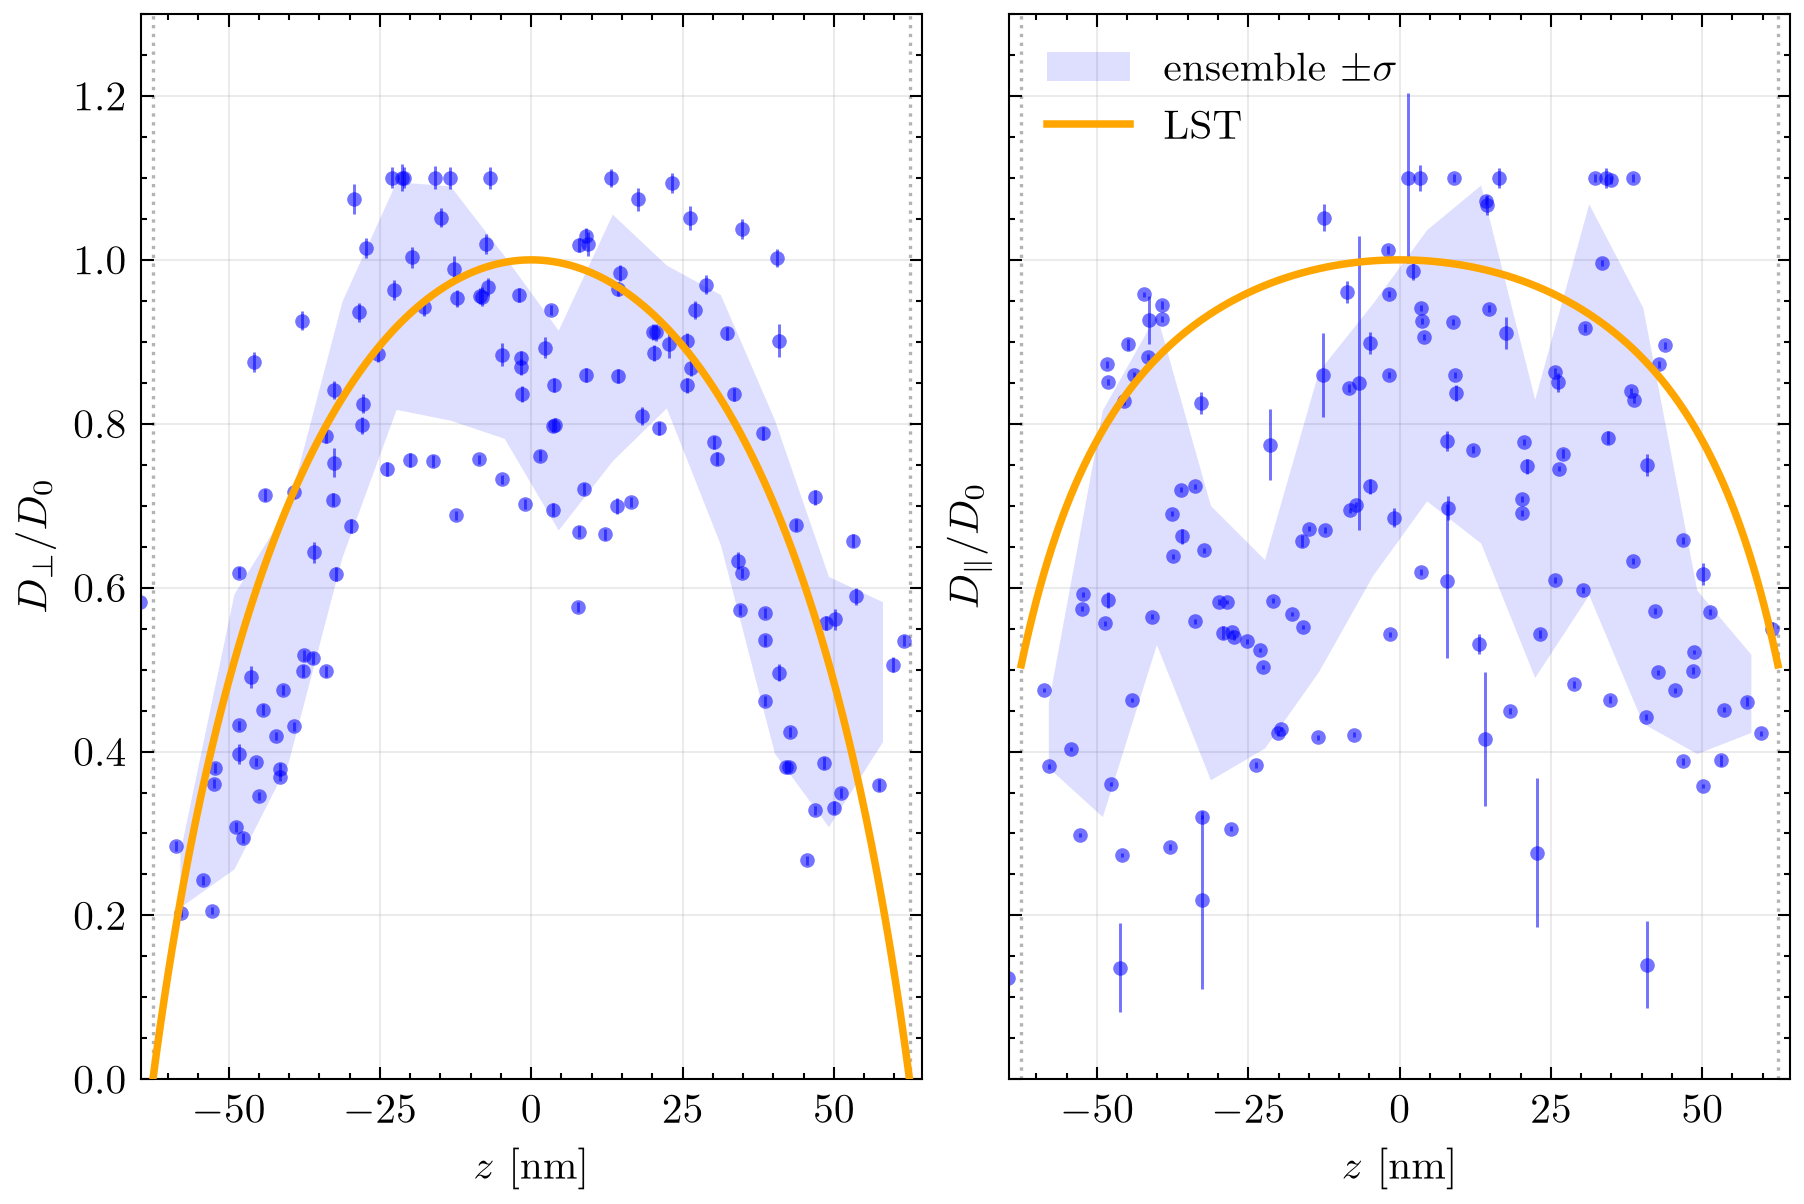

In [314]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

NB    = 14      # ensemble bins across the gap
MIN_N = 3       # min points per bin

edges = np.linspace(-h/2 + a, h/2 - a, NB + 1)
ctr   = 0.5 * (edges[1:] + edges[:-1])

def band(zlist, vlist):
    """Pooled points → binned mean ± std. No regridding, just binning."""
    Z = np.concatenate([np.ravel(z).astype(float) for z in zlist])
    V = np.concatenate([np.ravel(v).astype(float) for v in vlist])
    g = np.isfinite(Z) & np.isfinite(V)
    Z, V = Z[g], V[g]
    mu, *_ = binned_statistic(Z, V, 'mean',  bins=edges)
    sd, *_ = binned_statistic(Z, V, 'std',   bins=edges)
    n , *_ = binned_statistic(Z, V, 'count', bins=edges)
    k = n >= MIN_N
    return ctr[k], mu[k], sd[k]

cols = plt.cm.viridis(np.linspace(0.05, 0.9, len(zms)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 4), sharey=True,
                               constrained_layout=True, dpi=300)

panels = [(ax1, b1, b2, mob_tot_perp, r'$D_\perp/D_0$',     'perpendicular'),
          (ax2, a1, a2, mob_tot_parr, r'$D_\parallel/D_0$', 'parallel')]

for ax, vals, errs, theory, ylab, name in panels:
    # per-track points, faint
    for i, (z, v, e, c) in enumerate(zip(zms, vals, errs, cols)):
        ax.errorbar(z, v, yerr=e, linestyle='', marker='o', ms=3.5, color='blue',
                    alpha=0.55, elinewidth=0.7, capsize=0, mew=0, zorder=2)

    # ensemble mean ± spread
    zb, mu, sd = band(zms, vals)
    ax.fill_between(zb, mu - sd, mu + sd, color='blue', alpha=0.13, lw=0, zorder=3,
                    label=r'ensemble $\pm\sigma$')
    #ax.plot(zb, mu, color='k', lw=1.6, zorder=4, label='ensemble mean')

    ax.plot(z_vec - h/2, theory / np.max(theory), color='orange', lw=1.8,
            zorder=5, label=f'LST')

    for w in (-h/2 + a, h/2 - a):
        ax.axvline(w, color='0.7', lw=0.8, ls=':', zorder=1)

    ax.set(xlim=(-h/2 + a - 2, h/2 - a + 2), ylim=(0, 1.3),
           xlabel=r'$z$ [nm]', ylabel=ylab)
    ax.grid(alpha=0.25, lw=0.5)


ax2.legend(loc='upper left')

save_fig(fig, 'Figures/glycerol_diffusivity_relation', also='pdf')

# glycerol curve


In [315]:

def Cm(mass_gly, mass_h20):
    return mass_gly/(mass_gly + mass_h20)

def exp_alpha(Cm, T):
    a = 0.705 - 0.0017 * T
    b = (4.9 + 0.036 * T)*a**(2.5)
    frac = (a*Cm*(1-Cm))/(a*Cm + b*(1-Cm))
    return 1 - Cm + frac

def GetVisc(conc, T_C=22):
    alpha = exp_alpha(conc, T_C)
    mu_w = 1.790 * np.exp((-1230 * T_C) / (36100 + 360 * T_C))
    mu_g = 12100 * np.exp((-1233 * T_C) / (9900 + 70 * T_C))
    return (mu_w ** alpha ) * (mu_g ** (1-alpha))

mass_gly = np.linspace(0, 100, 100)
mass_h20 = np.ones(len(mass_gly)) * 100 - mass_gly
 
T = 22 #C

conc = Cm(mass_gly, mass_h20)
visc = GetVisc(conc, T_C= T)


WindowsPath('Figures/glycerol_curve.svg')

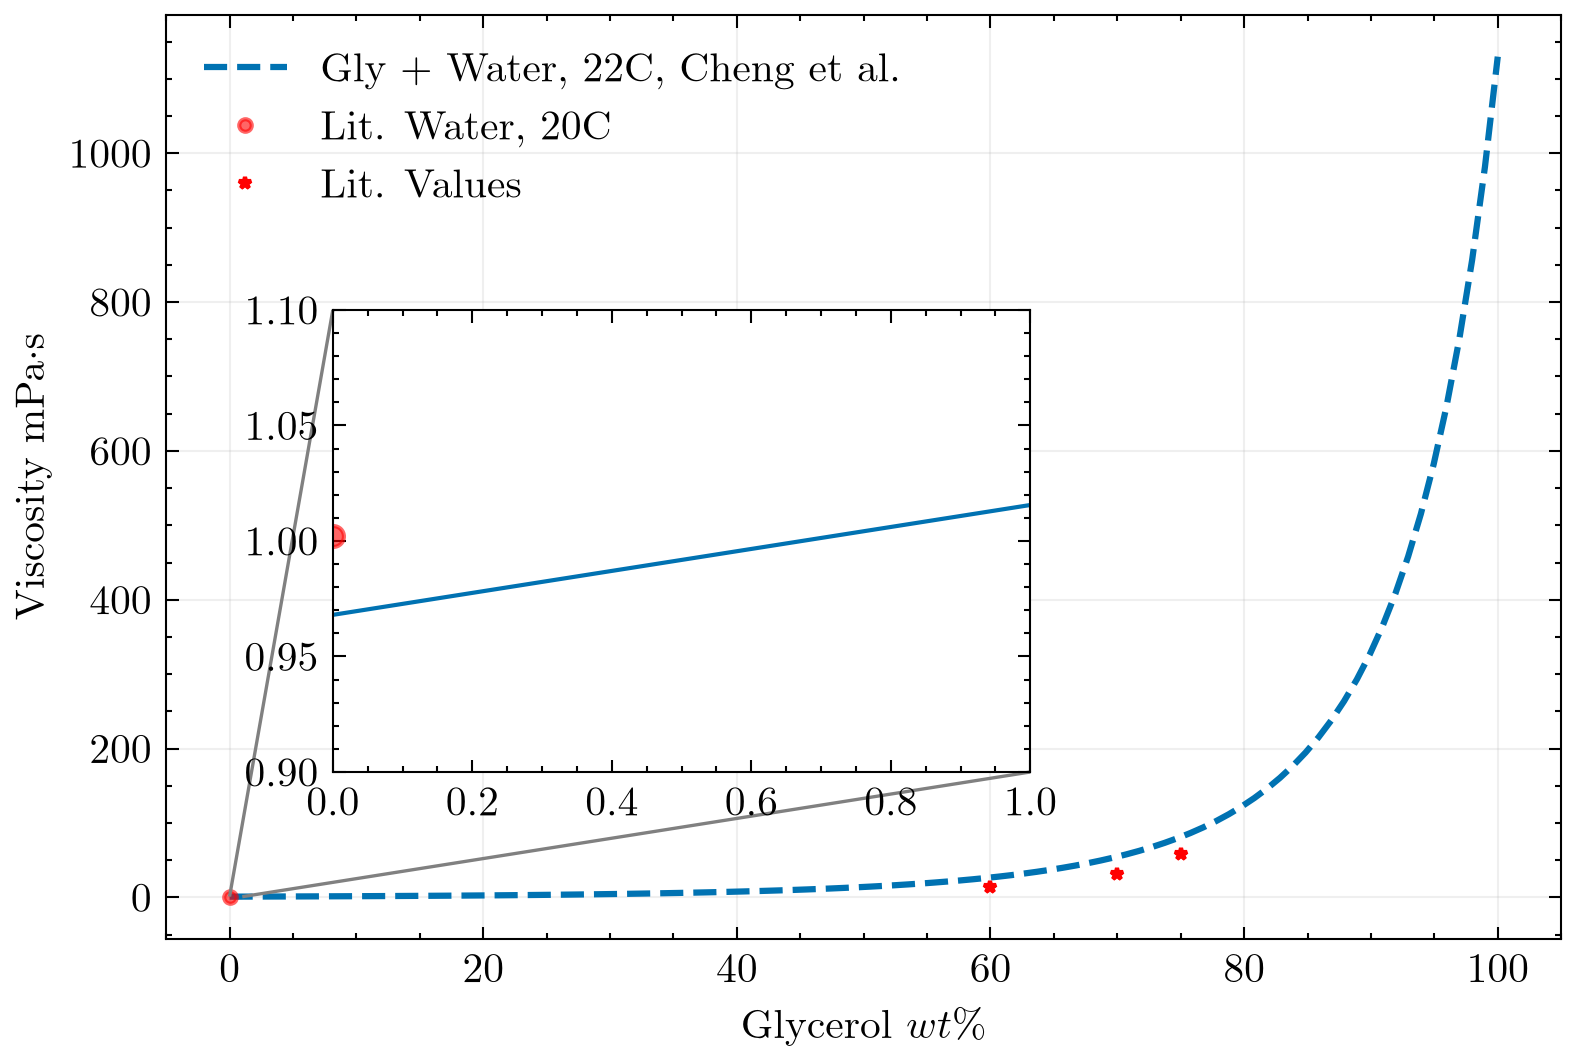

In [323]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

fig, ax = plt.subplots(dpi=300, figsize=(6,4))

# Main plot
ax.plot(conc*100, visc, lw=1.5, linestyle='dashed', label=f'Gly + Water, {T}C, Cheng et al. ')
ax.plot(0, 1.002, 'ro', markersize=3, alpha=0.6, label='Lit. Water, 20C')

ax.plot(np.array([60, 70, 75]), np.array([14.4, 31.9, 57.9]), 'r*', label='Lit. Values', markersize=3)

ax.set_ylabel(r'Viscosity mPa$\cdot$s')
ax.set_xlabel(r'Glycerol $wt\%$')

# Create inset (smaller + better placement)
ax_inset = inset_axes(ax, width="50%", height="50%", loc='lower left', borderpad=4)

ax_inset.plot(conc*100, visc, lw=1)
ax_inset.plot(0, 1.002, 'ro', markersize=5, alpha=0.6)

# Zoom region (convert to wt%)
ax_inset.set_xlim(0, 1)   # 0–11 wt%
ax_inset.set_ylim(0.9, 1.1)

# Reduce clutter
ax_inset.tick_params(labelsize=10)

# Draw box showing zoom region
mark_inset(ax, ax_inset, loc1=2, loc2=4, fc="none", ec="0.5", lw=0.8)

ax.legend()
ax.grid(alpha=0.2)


save_fig(fig, 'Figures/glycerol_curve', also='pdf')

# LNP dataset diffusion
